# 6 · Balanced growth, accumulation cycles and chaos

With cross-dual market prices (`market_prices = true`, after Flaschel and Semmler), market prices respond to sectoral excess demand, and capital moves on profit rates measured at those prices. This gives the coupled model interior **balanced-growth rays**, where all sectors grow at a common rate `g★`.

The right-hand side is homogeneous of degree 1, so balanced growth is a fixed point of the system normalized to the simplex. MarxKapital finds it, continues it in a parameter with BifurcationKit, and follows what happens when it loses stability: limit cycles, a torus, coexisting attractors and chaos.

This notebook reproduces, at a smaller scale, the analysis in Sections 3.6 and 5.6 of the paper. The two cells tagged `slow` take a few minutes in total.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, Random, LinearAlgebra
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

## 1. Balanced growth

The cross-dual state is `[C; V; q]`, with log market prices `q`. `β` is the speed of price adjustment and `μ_v` the mobility of variable capital (off by default).

In [2]:
Random.seed!(5)
sol, _, p = simulate_Ndept(6, T = 1.0, seed = 5, coupled = true, μ = 0.5,
                          market_prices = true)
X0 = sol.u[1]
pb = merge(p, (β = 0.1,))          # slower price adjustment, as in the paper
eq = balanced_growth(pb, X0)
(g★ = eq.g, r_aggregate = eq.r_aggregate, ω = eq.ω, stable = eq.stable, residual = eq.residual)

(g★ = 0.24403298748882543, r_aggregate = 0.3719065701061569, ω = 0.42155657220509113, stable = true, residual = 1.7668154028060382e-14)

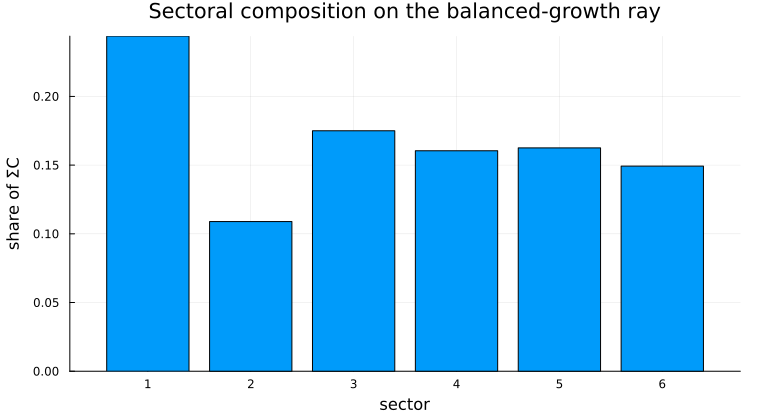

In [3]:
bar(eq.share_C, legend = false, xlabel = "sector", ylabel = "share of ΣC",
    title = "Sectoral composition on the balanced-growth ray")

## 2. Growth and distribution

`wage_sweep` continues balanced growth against the wage share. In the `:uniform` variant every sector gets the same wage share `ω` (`eᵢ = (1 − ω)/ω`); `:proportional` scales the sectoral rates of surplus value and keeps their differences.

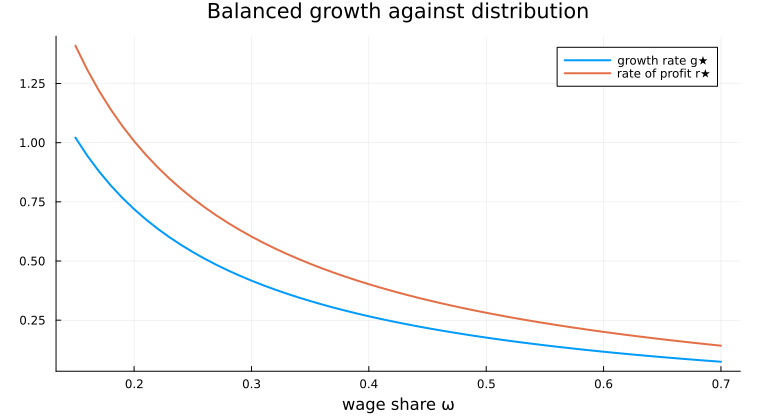

In [4]:
vs = wage_sweep(pb, X0; variant = :uniform)
plot(vs.ω, [vs.g vs.r], lw = 2, label = ["growth rate g★" "rate of profit r★"],
     xlabel = "wage share ω", title = "Balanced growth against distribution")

In [5]:
(all_stable = all(vs.stable), all_converged = all(vs.converged))

(all_stable = true, all_converged = true)

A higher wage share lowers both the growth rate and the rate of profit, and with `μ_v = 0` balanced growth is stable along the whole sweep.

## 3. The Hopf bifurcation in μ_v

`accumulation_bifurcation` continues balanced growth in `μ_v`, detects Hopf points with their first Lyapunov coefficient `l1` (`l1 < 0`: supercritical, a stable cycle is born), and continues the branch of limit cycles by orthogonal collocation, with stability from the Floquet multipliers. It takes about half a minute.

In [6]:
res = accumulation_bifurcation(pb, X0, :μ_v; interval = (0.0, 1.8), orbit_interval = (0.9, 1.3))
[(θ = round(h.θ, digits = 3), period = round(h.period, digits = 2),
  l1 = round(h.l1, digits = 3), supercritical = h.supercritical) for h in res.hopf]

5-element Vector{@NamedTuple{θ::Float64, period::Float64, l1::Float64, supercritical::Bool}}:
 (θ = 1.003, period = 20.89, l1 = -0.193, supercritical = 1)
 (θ = 1.071, period = 16.17, l1 = -0.143, supercritical = 1)
 (θ = 1.155, period = 14.96, l1 = -0.227, supercritical = 1)
 (θ = 1.336, period = 15.9, l1 = -0.133, supercritical = 1)
 (θ = 1.409, period = 12.34, l1 = -0.618, supercritical = 1)

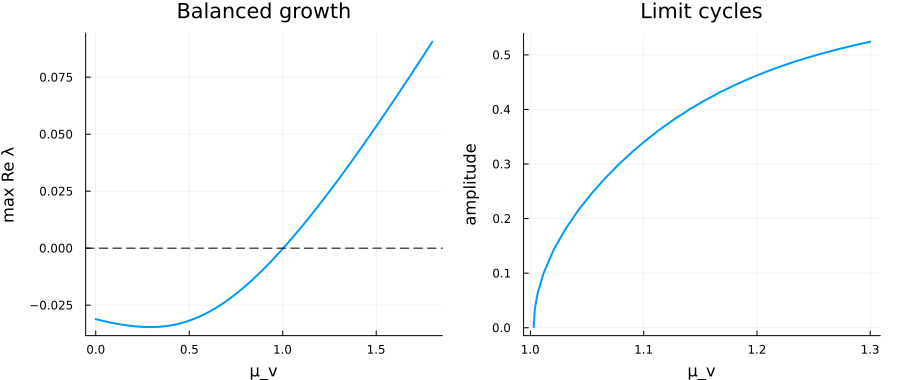

In [7]:
o = res.orbits
plot(plot(res.θ, res.max_real_part, lw = 2, legend = false, xlabel = "μ_v",
          ylabel = "max Re λ", title = "Balanced growth"),
     plot(o.θ, o.amplitude, lw = 2, legend = false, xlabel = "μ_v",
          ylabel = "amplitude", title = "Limit cycles"),
     layout = (1, 2), size = (900, 380))
hline!([0.0], subplot = 1, color = :black, ls = :dash)

`simulated_cycle` checks a cycle by direct simulation, with a Poincaré section: the period from the section crossings should match the collocation period.

In [8]:
cs = simulated_cycle(pb, :μ_v, 1.1, X0)
k = argmin(abs.(o.θ .- 1.1))
(simulated_period = cs.T_min, collocation_period = o.period[k], amplitude = cs.amplitude)

(simulated_period = 19.26, collocation_period = 19.225185691390546, amplitude = 0.3402109457486564)

## 4. Three regimes

Simulating the normalized system at three values of `μ_v`: convergence to balanced growth, a limit cycle, and irregular motion. We plot the constant capital of the first two sectors (normalized state). The stable case shows the whole run, spiralling into the balanced-growth point; the other two drop a transient of 1500 time units.

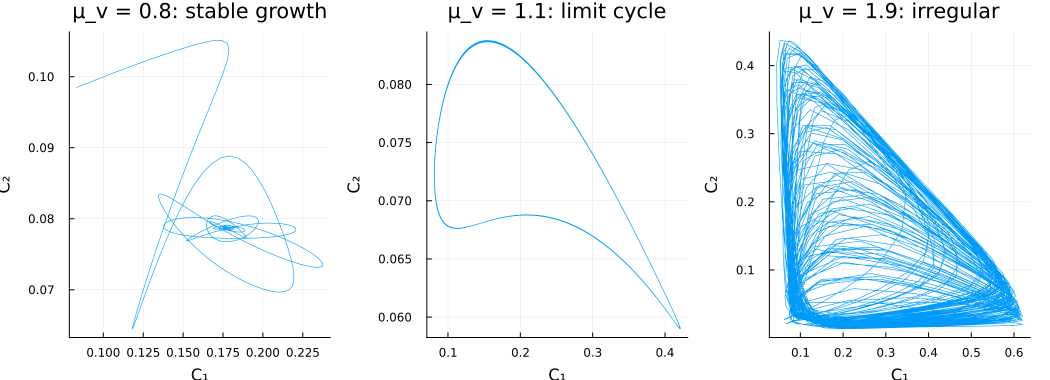

In [9]:
regimes = [(0.8, 0.0, "μ_v = 0.8: stable growth"), (1.1, 1500.0, "μ_v = 1.1: limit cycle"),
           (1.9, 1500.0, "μ_v = 1.9: irregular")]
plot([begin
          s = simulate_normalized(with_parameter(pb, :μ_v, θ), X0; T = 2500.0, saveat = 0.5)
          keep = s.t .>= t_from
          plot(s[1, keep], s[2, keep], title = title, legend = false, lw = 0.6,
               xlabel = "C₁", ylabel = "C₂")
      end for (θ, t_from, title) in regimes]..., layout = (1, 3), size = (1050, 380))

## 5. The Hopf boundary in the (ω, μ_v) plane

`hopf_curve` follows the first Hopf point as the uniform wage share changes. A higher wage share moves the boundary up. The smaller continuation step (`dsmax = 0.005`, against the default 0.01) keeps close pairs of eigenvalue crossings from being missed at some wage shares; the library warns when that happens.

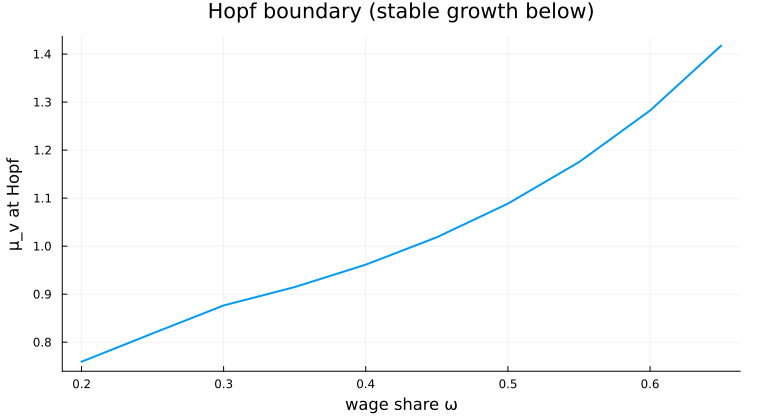

In [10]:
ch = hopf_curve(pb, X0; dsmax = 0.005)
plot(ch.ω, ch.μ_v_H, lw = 2, legend = false, xlabel = "wage share ω", ylabel = "μ_v at Hopf",
     title = "Hopf boundary (stable growth below)")

## 6. Is the irregular regime chaotic?

`lyapunov_exponents` computes the largest Lyapunov exponents with Benettin's method and the exact Jacobian. A limit cycle has `(0, −, −)`; chaos has a positive largest exponent, with the exponent along the flow near zero. This cell takes about two minutes.

In [11]:
ly = lyapunov_exponents(pb, :μ_v, 1.9, X0; T_transient = 2000.0, T = 10000.0)
ly.λ

3-element Vector{Float64}:
  0.027974403243524206
  0.00032634236425243933
 -0.0038385859467229898

## 7. Coexisting attractors

`simulated_hysteresis` sweeps `μ_v` up and then down, carrying the state from one step to the next. Where the two sweeps end on different attractors, a stable cycle and the torus coexist.

In [12]:
hs = simulated_hysteresis(pb, :μ_v, 1.34:0.02:1.48, X0; T_transient = 2000.0, T = 1500.0)
[(θ = θ, up = a, down = b) for (θ, a, b) in zip(hs.θ, hs.up.class, hs.down.class)]

8-element Vector{@NamedTuple{θ::Float64, up::Symbol, down::Symbol}}:
 (θ = 1.34, up = :irregular, down = :irregular)
 (θ = 1.36, up = :irregular, down = :irregular)
 (θ = 1.38, up = :irregular, down = :cycle)
 (θ = 1.4, up = :irregular, down = :cycle)
 (θ = 1.42, up = :irregular, down = :cycle)
 (θ = 1.44, up = :cycle, down = :cycle)
 (θ = 1.46, up = :cycle, down = :cycle)
 (θ = 1.48, up = :cycle, down = :cycle)

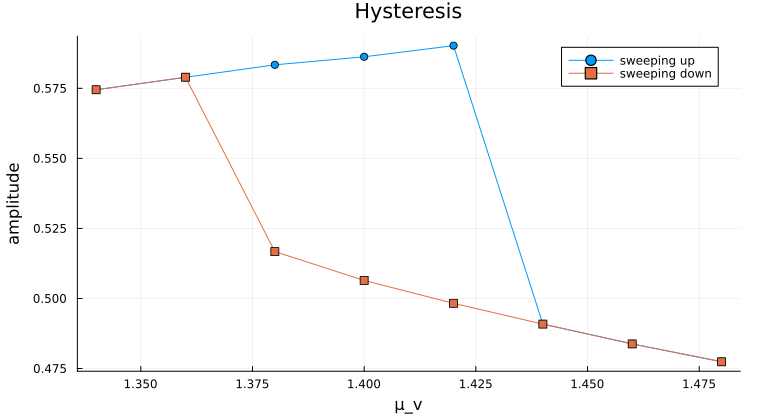

In [13]:
plot(hs.θ, hs.up.amplitude, marker = :circle, label = "sweeping up", xlabel = "μ_v",
     ylabel = "amplitude", title = "Hysteresis")
plot!(hs.θ, hs.down.amplitude, marker = :square, label = "sweeping down")